In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os
from google.colab import userdata

DRIVE = '/content/drive/MyDrive/drone-mapping'
os.makedirs(f'{DRIVE}/data', exist_ok=True)

os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
!pip install -q -U kaggle
!kaggle --version
print('Kaggle token ready')

Kaggle CLI 2.2.5
Kaggle token ready


In [3]:
ZIP = f'{DRIVE}/data/uavid-v1.zip'

if not os.path.exists(ZIP):
    !kaggle datasets download -d dasmehdixtr/uavid-v1 -p "{DRIVE}/data"
else:
    print('Already downloaded, skipping')

!ls -lh "{DRIVE}/data"

Dataset URL: https://www.kaggle.com/datasets/dasmehdixtr/uavid-v1
License(s): GPL-2.0
100% 10.9G/10.9G [02:28<00:00, 79.2MB/s]

total 11G
-rw------- 1 root root 11G Apr 16  2021 uavid-v1.zip


In [4]:
!unzip -q -o "{ZIP}" -d /content/uavid
print('Unzipped')

Unzipped


In [6]:
import cv2, numpy as np, glob

for root, dirs, files in os.walk('/content/uavid'):
    depth = root.replace('/content/uavid', '').count(os.sep)
    if depth <= 3:
        print('  ' * depth + os.path.basename(root) + f'/  ({len(files)} files)')

imgs = sorted(glob.glob('/content/uavid/**/*.png', recursive=True))
print('\nTotal PNGs:', len(imgs))
print('Example:', imgs[0])
sample = cv2.imread(imgs[0])
print('Shape:', sample.shape)

uavid/  (0 files)
  uavid_val/  (0 files)
    seq16/  (0 files)
      Images/  (70 files)
      Labels/  (70 files)
  uavid_train/  (0 files)
    seq1/  (0 files)
      Images/  (600 files)
      Labels/  (600 files)
  uavid_test/  (0 files)
    seq24/  (0 files)
      Images/  (10 files)
    seq22/  (0 files)
      Images/  (10 files)
    seq29/  (0 files)
      Images/  (10 files)
    seq21/  (0 files)
      Images/  (10 files)
    seq38/  (0 files)
      Images/  (10 files)
    seq26/  (0 files)
      Images/  (10 files)
    seq23/  (0 files)
      Images/  (10 files)
    seq30/  (0 files)
      Images/  (10 files)
    seq40/  (0 files)
      Images/  (10 files)
    seq39/  (0 files)
      Images/  (10 files)
    seq25/  (0 files)
      Images/  (10 files)
    seq28/  (0 files)
      Images/  (10 files)
    seq41/  (0 files)
      Images/  (10 files)
    seq27/  (0 files)
      Images/  (10 files)
    seq42/  (0 files)
      Images/  (10 files)

Total PNGs: 1490
Example: /content/ua

Train: 600 | Val: 70
First names: ['000000.png', '000100.png', '000200.png', '000300.png', '000400.png']
Last names: ['shifted95.png', 'shifted96.png', 'shifted97.png', 'shifted98.png', 'shifted99.png']
Exact duplicates inside train: 0
Train/val overlap: 0
Train shapes (every 50th): Counter({(2160, 3840, 3): 9, (2160, 4096, 3): 3})

Colours in first label:
(np.uint8(0), np.uint8(0), np.uint8(0)) 17.8%
(np.uint8(0), np.uint8(128), np.uint8(0)) 20.4%
(np.uint8(64), np.uint8(0), np.uint8(128)) 3.8%
(np.uint8(64), np.uint8(64), np.uint8(0)) 0.8%
(np.uint8(128), np.uint8(0), np.uint8(0)) 35.0%
(np.uint8(128), np.uint8(64), np.uint8(128)) 14.6%
(np.uint8(128), np.uint8(128), np.uint8(0)) 4.1%
(np.uint8(192), np.uint8(0), np.uint8(192)) 3.4%


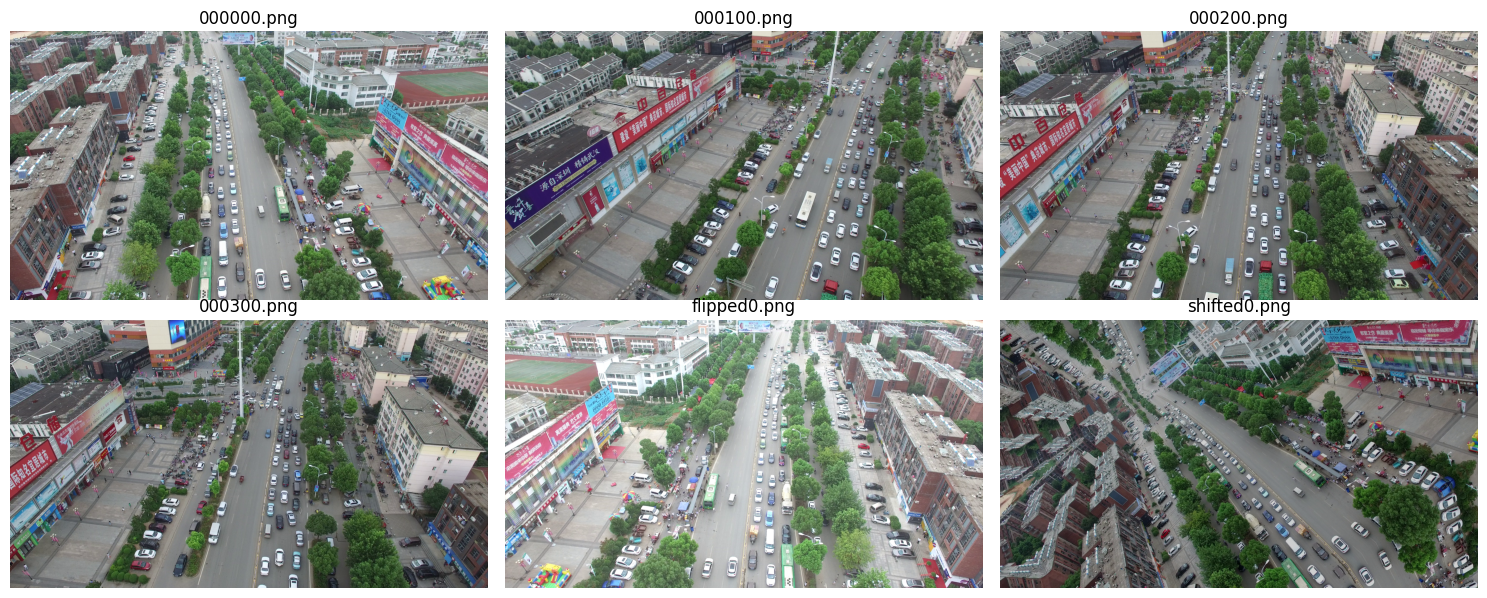

In [7]:
import hashlib, collections
import matplotlib.pyplot as plt

tr = sorted(glob.glob('/content/uavid/uavid_train/*/Images/*.png'))
va = sorted(glob.glob('/content/uavid/uavid_val/*/Images/*.png'))
print('Train:', len(tr), '| Val:', len(va))
print('First names:', [os.path.basename(p) for p in tr[:5]])
print('Last names:', [os.path.basename(p) for p in tr[-5:]])

def md5(p):
    return hashlib.md5(open(p, 'rb').read()).hexdigest()

tr_hash = [md5(p) for p in tr]
va_hash = set(md5(p) for p in va)
print('Exact duplicates inside train:', len(tr_hash) - len(set(tr_hash)))
print('Train/val overlap:', len(set(tr_hash) & va_hash))
print('Train shapes (every 50th):', collections.Counter(cv2.imread(p).shape for p in tr[::50]))

# Label colours in one mask
lab = cv2.cvtColor(cv2.imread(tr[0].replace('/Images/', '/Labels/')), cv2.COLOR_BGR2RGB)
cols, cnts = np.unique(lab.reshape(-1, 3), axis=0, return_counts=True)
print('\nColours in first label:')
for c, n in zip(cols, cnts):
    print(tuple(c), f'{100*n/cnts.sum():.1f}%')

# Look for flipped/rotated copies
idx = [0, 1, 2, 3, 200, 400]
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for a, i in zip(ax.flat, idx):
    a.imshow(cv2.cvtColor(cv2.imread(tr[i]), cv2.COLOR_BGR2RGB))
    a.set_title(os.path.basename(tr[i])); a.axis('off')
plt.tight_layout(); plt.show()

In [8]:
CLASSES = ['Clutter', 'Building', 'Road', 'Tree', 'LowVeg', 'MovingCar', 'StaticCar', 'Human']
COLORS = [(0,0,0), (128,0,0), (128,64,128), (0,128,0),
          (128,128,0), (64,0,128), (192,0,192), (64,64,0)]   # RGB

TILE, SCALE, OUT = 512, 0.5, '/content/tiles'

def rgb_to_id(lab_rgb):
    out = np.full(lab_rgb.shape[:2], 255, np.uint8)   # 255 = unknown colour, ignored in training
    for cid, c in enumerate(COLORS):
        out[np.all(lab_rgb == c, axis=-1)] = cid
    return out

def starts(total, tile):
    s = list(range(0, total - tile + 1, tile))
    if s[-1] != total - tile:
        s.append(total - tile)   # last tile overlaps slightly so the edge is covered
    return s

def tile_split(paths, split):
    os.makedirs(f'{OUT}/{split}/images', exist_ok=True)
    os.makedirs(f'{OUT}/{split}/labels', exist_ok=True)
    n, unknown = 0, 0
    for p in paths:
        img = cv2.imread(p)
        lab = cv2.cvtColor(cv2.imread(p.replace('/Images/', '/Labels/')), cv2.COLOR_BGR2RGB)
        lab_id = rgb_to_id(lab)
        img = cv2.resize(img, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA)
        lab_id = cv2.resize(lab_id, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
        unknown += int((lab_id == 255).sum())
        seq, stem = p.split('/')[-3], os.path.basename(p)[:-4]
        H, W = img.shape[:2]
        for y in starts(H, TILE):
            for x in starts(W, TILE):
                name = f'{seq}_{stem}_{y}_{x}'
                cv2.imwrite(f'{OUT}/{split}/images/{name}.jpg', img[y:y+TILE, x:x+TILE],
                            [cv2.IMWRITE_JPEG_QUALITY, 95])
                cv2.imwrite(f'{OUT}/{split}/labels/{name}.png', lab_id[y:y+TILE, x:x+TILE])
                n += 1
    print(f'{split}: {n} tiles | unknown-colour pixels: {unknown}')

tile_split(tr, 'train')
tile_split(va, 'val')

# Class balance on train tiles
counts = np.zeros(256, np.int64)
for f in glob.glob(f'{OUT}/train/labels/*.png'):
    counts += np.bincount(cv2.imread(f, 0).ravel(), minlength=256)
total = counts[:8].sum()
print('\nTrain class distribution:')
for i, c in enumerate(CLASSES):
    print(f'{c:10s} {100*counts[i]/total:5.2f}%')

# Save tiles to Drive so you never redo this
!cd /content && zip -q -r "{DRIVE}/data/tiles_512.zip" tiles
!ls -lh "{DRIVE}/data"

train: 7200 tiles | unknown-colour pixels: 0
val: 840 tiles | unknown-colour pixels: 0

Train class distribution:
Clutter    17.98%
Building   25.39%
Road       14.53%
Tree       25.19%
LowVeg     14.49%
MovingCar   1.05%
StaticCar   1.25%
Human       0.12%
total 12G
-rw------- 1 root root 1.1G Nov  3 10:28 tiles_512.zip
-rw------- 1 root root  11G Apr 16  2021 uavid-v1.zip
